# Keras CNN - EuroSAT 이미지 분류
Conv2D + BatchNorm + MaxPooling을 3단 쌓은 CNN입니다. ANN/DNN과 파라미터 수, 정확도를 비교하기 위한 핵심 모델입니다.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, shutil

SPLIT_DIR = '/content/eurosat_split'
DRIVE_ZIP = '/content/drive/MyDrive/eurosat_split.zip'

if not os.path.exists(SPLIT_DIR) and os.path.exists(DRIVE_ZIP):
    shutil.unpack_archive(DRIVE_ZIP, SPLIT_DIR)
    print('Drive에서 압축 해제 완료')
else:
    print('SPLIT_DIR:', SPLIT_DIR)

Mounted at /content/drive
Drive에서 압축 해제 완료


In [ ]:
import tensorflow as tf

print('GPU 사용 가능:', tf.config.list_physical_devices('GPU'))

IMG_SIZE = (64, 64)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(SPLIT_DIR, 'train'), image_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=42)
val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(SPLIT_DIR, 'val'), image_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=42)
test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(SPLIT_DIR, 'test'), image_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=42)

class_names = train_ds.class_names
num_classes = len(class_names)
print('클래스 수:', num_classes)

GPU 사용 가능: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Found 18900 files belonging to 10 classes.
Found 4050 files belonging to 10 classes.
Found 4050 files belonging to 10 classes.
클래스 수: 10


In [ ]:
normalization_layer = tf.keras.layers.Rescaling(1./255)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y)).cache().prefetch(AUTOTUNE)
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y)).cache().prefetch(AUTOTUNE)
test_ds = test_ds.map(lambda x, y: (normalization_layer(x), y)).cache().prefetch(AUTOTUNE)

## CNN 모델 정의
Conv2D-BatchNorm-ReLU-MaxPooling 블록을 3번 쌓고, Flatten 후 Dense층을 거칩니다.

In [ ]:
def build_cnn(input_shape, num_classes):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=input_shape),

        tf.keras.layers.Conv2D(32, 3, padding='same', activation='relu', kernel_initializer='he_normal'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D(2),

        tf.keras.layers.Conv2D(64, 3, padding='same', activation='relu', kernel_initializer='he_normal'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D(2),

        tf.keras.layers.Conv2D(128, 3, padding='same', activation='relu', kernel_initializer='he_normal'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D(2),

        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(256, activation='relu', kernel_initializer='he_normal'),
        tf.keras.layers.Dropout(0.5),
        tf.keras.layers.Dense(num_classes, activation='softmax'),
    ])
    return model

model = build_cnn((64, 64, 3), num_classes)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,194,122 (8.37 MB)

 Trainable params: 2,193,674 (8.37 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=3),
]

In [ ]:
import time

start_time = time.time()
history = model.fit(train_ds, validation_data=val_ds, epochs=50, callbacks=callbacks)
training_time = time.time() - start_time
print(f'학습 시간: {training_time:.1f}초')

Epoch 1/50
591/591 ━━━━━━━━━━━━━━━━━━━━ 20s 21ms/step - accuracy: 0.5261 - loss: 1.5310 - val_accuracy: 0.6269 - val_loss: 1.0143 - learning_rate: 0.0010
Epoch 2/50
591/591 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.6441 - loss: 1.0148 - val_accuracy: 0.7269 - val_loss: 0.7763 - learning_rate: 0.0010
Epoch 3/50
591/591 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.7001 - loss: 0.8628 - val_accuracy: 0.7232 - val_loss: 0.8289 - learning_rate: 0.0010
Epoch 4/50
591/591 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.7410 - loss: 0.7506 - val_accuracy: 0.7435 - val_loss: 0.7831 - learning_rate: 0.0010
Epoch 5/50
591/591 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.7795 - loss: 0.6573 - val_accuracy: 0.6217 - val_loss: 1.4484 - learning_rate: 0.0010
Epoch 6/50
591/591 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8393 - loss: 0.4709 - val_accuracy: 0.8625 - val_loss: 0.4302 - learning_rate: 5.0000e-04
Epoch 7/50
591/591 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.8585 - loss: 0.4

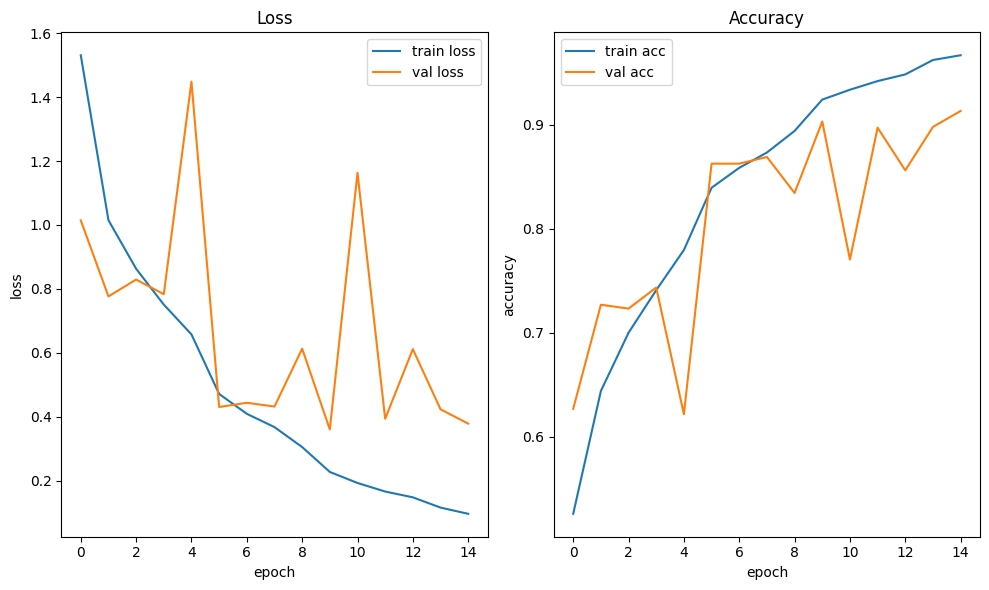

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
axes[0].plot(history.history['loss'], label='train loss')
axes[0].plot(history.history['val_loss'], label='val loss')
axes[0].set_xlabel('epoch'); axes[0].set_ylabel('loss'); axes[0].legend(); axes[0].set_title('Loss')
axes[1].plot(history.history['accuracy'], label='train acc')
axes[1].plot(history.history['val_accuracy'], label='val acc')
axes[1].set_xlabel('epoch'); axes[1].set_ylabel('accuracy'); axes[1].legend(); axes[1].set_title('Accuracy')
plt.tight_layout();
plt.savefig('/content/keras_cnn_curve.jpg', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(test_ds)
num_params = model.count_params()
print(f'Test accuracy: {test_acc:.4f}')
print(f'Test loss: {test_loss:.4f}')
print(f'파라미터 수: {num_params:,}')

127/127 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9094 - loss: 0.3117
Test accuracy: 0.9094
Test loss: 0.3117
파라미터 수: 2,194,122


In [ ]:
import pandas as pd

RESULTS_PATH = '/content/drive/MyDrive/model_results.csv'
row = {
    'model': 'CNN', 'framework': 'Keras',
    'test_accuracy': test_acc, 'test_loss': test_loss,
    'num_params': num_params, 'training_time_sec': training_time,
    'epochs_ran': len(history.history['loss']),
}

if os.path.exists(RESULTS_PATH):
    results_df = pd.read_csv(RESULTS_PATH)
    results_df = results_df[~((results_df['model'] == row['model']) & (results_df['framework'] == row['framework']))]
    results_df = pd.concat([results_df, pd.DataFrame([row])], ignore_index=True)
else:
    results_df = pd.DataFrame([row])

results_df.to_csv(RESULTS_PATH, index=False)
results_df

,model,framework,test_accuracy,test_loss,num_params,training_time_sec,epochs_ran
0,ANN,Keras,0.273827,1.791635,3148554,65.389723,28
1,DNN,Keras,0.390864,1.600345,6457482,71.961101,23
2,ANN,PyTorch,0.216296,1.917291,3148554,130.308418,11
3,DNN,PyTorch,0.290617,1.760557,6457482,144.349892,11
4,CNN,PyTorch,0.929136,0.215957,2193674,491.769829,31
5,CNN,Keras,0.909383,0.311695,2194122,87.861347,15


In [ ]:
KERAS_CNN_PATH = '/content/drive/MyDrive/keras_cnn_model.keras'
model.save(KERAS_CNN_PATH)
print('저장 완료:', KERAS_CNN_PATH)

저장 완료: /content/drive/MyDrive/keras_cnn_model.keras
